# 03 Job recommendation models

**The task.** Read one resume, then pick the 10 best jobs out of every job in the data
(about 43,000). We check whether the job the person was really invited to is in that list.

| Model | How it picks jobs |
|---|---|
| Random | picks jobs at random, the floor every model must beat |
| M0 Popularity | the jobs with the most invitations, same list for everyone |
| M1 TF-IDF title | compares the desired job title with job titles |
| M2 TF-IDF text | compares title + resume text with title + job text |
| M3 BM25 text | same text as M2, a different word weighting |
| M4 Popularity + region | the most invited jobs in the applicant's own region, no resume |
| M5 TF-IDF text + region | M2, but jobs in the applicant's own region come first |

Needs only pandas, numpy, scikit-learn and matplotlib. Takes about 3 to 5 minutes.

> **Stage 1, original study (restored).** Random, M0 to M5 baselines with their saved outputs.
> Metric tables are written to `results/baselines/` (the historical reference). The current authoritative results are in `results/final/`, produced by `python -m recommender.pipeline`.

## 0. Setup

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

if Path.cwd().name == "notebooks":
    os.chdir("..")

os.makedirs("results/baselines", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

K_LIST     = [5, 10, 20]   # we score the top 5, top 10 and top 20
TEST_SHARE = 0.20          # 20% of applicants are kept for testing
USE_SKILLS = True          # add the skill lists to the text (set False to compare)
SEED       = 42

print("project folder:", os.getcwd())

project folder: /Users/anantaupadhyaya/Downloads/job-recommendation-salary-analyzer


## 1. Load the clean data

In [2]:
df = pd.read_csv("data/processed/d4_clean.csv", encoding="utf-8-sig",
                 keep_default_na=False, low_memory=False)
df["is_positive"] = df["is_positive"].astype(int)

print(f"applications: {len(df):,}")
print(f"applicants  : {df['idCv'].nunique():,}")
print(f"jobs        : {df['idVacancy'].nunique():,}")

applications: 93,755
applicants  : 65,714
jobs        : 43,756


## 2. Build the text each model reads

The job title is the strongest signal, so we repeat it three times to give it more weight.

In [3]:
def clean_title(titles):
    return (titles.str.lower()
                  .str.replace(r"[^a-zа-яё0-9\s]", " ", regex=True)
                  .str.split().str.join(" "))

def make_text(title, body, skills):
    text = (clean_title(title) + " ") * 3 + body
    if USE_SKILLS:
        text = text + " " + skills
    return text.str.strip()

def region_key(regions):
    # "Томская область, Колпашевский район, г Колпашево" -> "томская область"
    # localityName holds region, district and city; regionName holds only the region
    return (regions.astype(str)
                   .str.split(",").str[0]
                   .str.lower()
                   .str.replace("-", " ")
                   .str.replace(r"^(город|г)\s+", "", regex=True)
                   .str.split().str.join(" "))

df["query"] = make_text(df["positionName"], df["cv_text"], df["cv_skills"])
df["doc"]   = make_text(df["vacancyName"], df["job_text"], df["job_skills"])

print("applicant text:", df["query"].iloc[0][:150])
print("job text      :", df["doc"].iloc[0][:150])

applicant text: электрик электрик электрик электрик электрик обслуживание трансформаторных подстанций электромонтёр технический лицей 6
job text      : электромонтер по ремонту и обслуживанию электрооборудования 6 разряда электромонтер по ремонту и обслуживанию электрооборудования 6 разряда электромон


## 3. The job pool

In [4]:
jobs = df.drop_duplicates("idVacancy").reset_index(drop=True)
job_row = pd.Series(jobs.index, index=jobs["idVacancy"])   # idVacancy -> row number in jobs
N_JOBS = len(jobs)

show_job = jobs["vacancyName_en"]   # English where we have it, for printing only

print(f"jobs in the pool: {N_JOBS:,}")
print(f"random guessing gets about {10 / N_JOBS:.5f} for Recall@10")

jobs in the pool: 43,756
random guessing gets about 0.00023 for Recall@10


### Near-identical job postings

Many postings have the same title in the same region and differ only by their id.
If the right answer is one of 12 identical postings, no model can know which one,
because the text is the same.

So we score every model in two ways:

| | Counts as correct when |
|---|---|
| **Strict** | the model finds the exact posting (`idVacancy`) |
| **Grouped** | the model finds a job with the same title in the same region |

For Grouped we also drop repeated postings from the list, as a real website would.

In [5]:
group_key = clean_title(jobs["vacancyName"]) + " | " + region_key(jobs["regionName"])
jobs["group"] = pd.factorize(group_key)[0]
group = jobs["group"].to_numpy()

sizes = jobs["group"].value_counts()
print(f"{N_JOBS:,} postings fall into {sizes.size:,} groups")
print(f"biggest group: {sizes.iloc[0]} identical postings")
print()
print("largest groups:")
for g, n in sizes.head(5).items():
    first = jobs[jobs["group"] == g].iloc[0]
    print(f"  {n:4d} x  {first['vacancyName_en'][:45]}  [{first['regionName'][:25]}]")

43,756 postings fall into 26,202 groups
biggest group: 94 identical postings

largest groups:
    94 x  Accountant  [Город Санкт-Петербург]
    92 x  Accountant  [Челябинская область]
    71 x  Car driver  [Пермский край]
    68 x  Accountant  [Пермский край]
    65 x  Kindergarten assistant  [Город Санкт-Петербург]


## 4. Split applicants into train and test

One person must be on one side only. If the same person were on both sides,
the model would have seen the answer.

Only the popularity model uses the training side. The text models do not learn
from labels, they only compare words.

In [6]:
eval_ids = df.loc[df["in_eval_set"].astype(int) == 1, "idCv"].unique()
eval_ids = np.sort(eval_ids)

rng = np.random.default_rng(SEED)
shuffled = rng.permutation(eval_ids)
n_test = int(len(shuffled) * TEST_SHARE)

test_ids  = np.sort(shuffled[:n_test])
train_ids = np.sort(shuffled[n_test:])

assert len(set(test_ids) & set(train_ids)) == 0   # nobody on both sides

print(f"applicants we can evaluate: {len(eval_ids):,}")
print(f"train: {len(train_ids):,}   test: {len(test_ids):,}")

applicants we can evaluate: 14,033
train: 11,227   test: 2,806


In [7]:
# one row per test applicant
test = df[df["idCv"].isin(test_ids)].drop_duplicates("idCv")
test = test.set_index("idCv").loc[test_ids].reset_index()

# the right answers: jobs each test applicant was invited to
invited = df[(df["is_positive"] == 1) & df["idCv"].isin(test_ids)]
answers = invited.groupby("idCv")["idVacancy"].apply(list)

gold_rows   = [[job_row[v] for v in answers[c]] for c in test["idCv"]]      # for Strict
gold_groups = [sorted(set(group[r] for r in rows)) for rows in gold_rows]  # for Grouped

look_alikes = [sizes[group[r]] for rows in gold_rows for r in rows]
print(f"test applicants: {len(test):,}")
print(f"right answers that have identical look-alike postings: {np.mean(np.array(look_alikes) > 1):.1%}")

test applicants: 2,806
right answers that have identical look-alike postings: 61.9%


## 5. How we score a list

- **Recall@K**: what share of the right answers is in the top K. The main number.
- **Precision@K**: what share of the K recommendations is right.
- **NDCG@K**: like Recall, but a right answer at rank 1 counts more than at rank 10.

In [8]:
def evaluate(ranked_lists, gold_lists):
    result = {}
    for k in K_LIST:
        recall, precision, ndcg = [], [], []
        for ranked, gold in zip(ranked_lists, gold_lists):
            gold = set(gold)
            hits = [1 if item in gold else 0 for item in list(ranked)[:k]]

            recall.append(sum(hits) / len(gold))
            precision.append(sum(hits) / k)

            dcg   = sum(h / np.log2(i + 2) for i, h in enumerate(hits))
            ideal = sum(1 / np.log2(i + 2) for i in range(min(k, len(gold))))
            ndcg.append(dcg / ideal)

        result[f"Recall@{k}"]    = np.mean(recall)
        result[f"Precision@{k}"] = np.mean(precision)
        result[f"NDCG@{k}"]      = np.mean(ndcg)
    return result

def drop_repeats(top_rows, k=max(K_LIST)):
    # keep the first posting of each group, so the list has no identical postings
    lists = []
    for rows in top_rows:
        seen, kept = set(), []
        for r in rows:
            if group[r] not in seen:
                seen.add(group[r])
                kept.append(group[r])
            if len(kept) == k:
                break
        lists.append(kept)
    return lists

### The scoring loop

We score 250 applicants at a time so the computer does not run out of memory.
We keep the top 300 so that after dropping repeats there are still at least 20 left.

In [9]:
# region of every job and every test applicant, as numbers so they compare fast
all_regions = pd.concat([region_key(jobs["regionName"]), region_key(test["localityName"])])
region_id = {name: i for i, name in enumerate(all_regions.unique())}
job_region = region_key(jobs["regionName"]).map(region_id).to_numpy()
cv_region  = region_key(test["localityName"]).map(region_id).to_numpy()

def top_jobs(Q, D, keep=300, same_region_first=False):
    best = []
    for start in range(0, Q.shape[0], 250):
        scores = (Q[start:start + 250] @ D.T).toarray()
        if same_region_first:
            other = cv_region[start:start + 250, None] != job_region[None, :]
            scores[other] -= 10            # jobs in other regions go to the bottom
        best.append(np.argsort(-scores, axis=1)[:, :keep])
    return np.vstack(best)

top = {}   # model name -> top 300 job rows for every test applicant

## 6. Random and M0 Popularity

In [10]:
rng = np.random.default_rng(SEED)
top["Random"] = np.array([rng.choice(N_JOBS, 300, replace=False) for _ in range(len(test))])

# count invitations per job, using training applicants only
train_inv = df[(df["is_positive"] == 1) & df["idCv"].isin(train_ids)]
counts = train_inv["idVacancy"].map(job_row).dropna().astype(int).value_counts()

popularity = np.zeros(N_JOBS)
popularity[counts.index] = counts.values
popular_rows = np.argsort(-popularity)[:300]
top["M0 Popularity"] = np.tile(popular_rows, (len(test), 1))

print("most invited jobs:")
for r in popular_rows[:5]:
    print(f"  {int(popularity[r]):4d} invitations  {show_job[r]}")

most invited jobs:
    96 invitations  Accountant
    68 invitations  Economist
    56 invitations  Real estate specialist
    36 invitations  Security guard
    36 invitations  Administrator and cashier


## 7. M1 TF-IDF, job title only

TF-IDF gives rare words more weight. A common word like `специалист` (specialist)
gets little weight, a specific word like `рентгенолог` (radiologist) gets a lot.

In [11]:
t0 = time.time()
tfidf_title = TfidfVectorizer(min_df=2, sublinear_tf=True, dtype=np.float32)
D_title = tfidf_title.fit_transform(clean_title(jobs["vacancyName"]))
Q_title = tfidf_title.transform(clean_title(test["positionName"]))

top["M1 TF-IDF title"] = top_jobs(Q_title, D_title)
print(f"words: {len(tfidf_title.vocabulary_):,}   time: {time.time() - t0:.0f}s")

words: 4,078   time: 5s


## 8. M2 TF-IDF, title + text

In [12]:
t0 = time.time()
tfidf = TfidfVectorizer(min_df=3, max_features=120_000, sublinear_tf=True, dtype=np.float32)
D_text = tfidf.fit_transform(jobs["doc"])
Q_text = tfidf.transform(test["query"])

top["M2 TF-IDF text"] = top_jobs(Q_text, D_text)
print(f"words: {len(tfidf.vocabulary_):,}   time: {time.time() - t0:.0f}s")

words: 32,416   time: 14s


## 9. M3 BM25, title + text

BM25 differs from TF-IDF in two ways:

1. A word that appears 10 times does not count 10 times as much. The effect levels off (`K1`).
2. Long job texts are not punished as hard (`B`).

In [13]:
t0 = time.time()
K1, B = 1.5, 0.75

counter = CountVectorizer(min_df=3, max_features=120_000, dtype=np.float32)
D_bm25 = counter.fit_transform(jobs["doc"]).tocsr()
Q_bm25 = counter.transform(test["query"])

n_docs  = D_bm25.shape[0]
doc_len = np.asarray(D_bm25.sum(axis=1)).ravel()
avg_len = doc_len.mean()

docs_with_word = np.bincount(D_bm25.indices, minlength=D_bm25.shape[1])
idf = np.log(1 + (n_docs - docs_with_word + 0.5) / (docs_with_word + 0.5))

# which job each stored number belongs to
row_of_value = np.repeat(np.arange(n_docs), np.diff(D_bm25.indptr))
tf = D_bm25.data
D_bm25.data = (idf[D_bm25.indices] * tf * (K1 + 1)
               / (tf + K1 * (1 - B + B * doc_len[row_of_value] / avg_len))).astype(np.float32)

top["M3 BM25 text"] = top_jobs(Q_bm25, D_bm25)
print(f"average job text length: {avg_len:.0f} words   time: {time.time() - t0:.0f}s")

average job text length: 71 words   time: 13s


## 10. M4 Popularity + region

Region is used as a filter, not as something the model learns. It works like a person
choosing "show me jobs in my region" on a job website.

This model does not read the resume at all. It shows the most invited jobs in the
applicant's own region. It tells us how much the region filter gives on its own,
so we can see how much the text adds in M5.

In [14]:
own_region = np.mean([any(job_region[r] == cv_region[i] for r in rows)
                      for i, rows in enumerate(gold_rows)])
print(f"test applicants invited to at least one job in their own region: {own_region:.1%}")
print("(this is the most a region filter can help; the rest were invited elsewhere)")

best = []
for start in range(0, len(test), 250):
    region_part = cv_region[start:start + 250]
    scores = np.tile(popularity, (len(region_part), 1))
    other = region_part[:, None] != job_region[None, :]
    scores[other] -= 1_000_000          # jobs in other regions go to the bottom
    best.append(np.argsort(-scores, axis=1)[:, :300])
top["M4 Popularity + region"] = np.vstack(best)
print("done")

test applicants invited to at least one job in their own region: 84.0%
(this is the most a region filter can help; the rest were invited elsewhere)
done


## 11. M5 TF-IDF text + region

The same text model as M2, with the same region filter as M4.
If M5 beats M4, the resume text helps on top of the region.

In [15]:
t0 = time.time()
top["M5 TF-IDF text + region"] = top_jobs(Q_text, D_text, same_region_first=True)
print(f"time: {time.time() - t0:.0f}s")

time: 12s


## 12. Results

In [16]:
strict, grouped = {}, {}
for name, rows in top.items():
    strict[name]  = evaluate([r[:max(K_LIST)] for r in rows], gold_rows)
    grouped[name] = evaluate(drop_repeats(rows), gold_groups)

columns = [f"{m}@{k}" for k in K_LIST for m in ["Recall", "Precision", "NDCG"]]
strict  = pd.DataFrame(strict).T[columns]
grouped = pd.DataFrame(grouped).T[columns]

pd.set_option("display.float_format", "{:.4f}".format)
print("STRICT: must find the exact posting")
strict

STRICT: must find the exact posting


,Recall@5,Precision@5,NDCG@5,Recall@10,Precision@10,NDCG@10,Recall@20,Precision@20,NDCG@20
Random,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0007,0.0000,0.0002
M0 Popularity,0.0260,0.0053,0.0177,0.0353,0.0037,0.0208,0.0613,0.0032,0.0273
M1 TF-IDF title,0.0306,0.0066,0.0181,0.0468,0.0050,0.0232,0.0727,0.0038,0.0296
M2 TF-IDF text,0.0261,0.0055,0.0173,0.0447,0.0047,0.0233,0.0736,0.0039,0.0306
M3 BM25 text,0.0282,0.0061,0.0190,0.0451,0.0048,0.0244,0.0694,0.0037,0.0306
M4 Popularity + region,0.1044,0.0215,0.0757,0.1413,0.0146,0.0875,0.1828,0.0095,0.0982
M5 TF-IDF text + region,0.1958,0.0409,0.1381,0.2662,0.0280,0.1614,0.3561,0.0187,0.1844


In [17]:
print("GROUPED: same title in the same region counts, repeated postings removed")
grouped

GROUPED: same title in the same region counts, repeated postings removed


,Recall@5,Precision@5,NDCG@5,Recall@10,Precision@10,NDCG@10,Recall@20,Precision@20,NDCG@20
Random,0.0012,0.0003,0.0007,0.0032,0.0004,0.0014,0.0057,0.0003,0.0020
M0 Popularity,0.0282,0.0058,0.0197,0.0449,0.0047,0.0251,0.0775,0.0040,0.0334
M1 TF-IDF title,0.0839,0.0175,0.0519,0.1334,0.0139,0.0680,0.1930,0.0100,0.0833
M2 TF-IDF text,0.0776,0.0163,0.0496,0.1339,0.0139,0.0679,0.2141,0.0112,0.0882
M3 BM25 text,0.0875,0.0184,0.0567,0.1328,0.0139,0.0712,0.2002,0.0104,0.0882
M4 Popularity + region,0.1377,0.0282,0.0992,0.1908,0.0197,0.1162,0.2552,0.0132,0.1325
M5 TF-IDF text + region,0.3926,0.0812,0.3201,0.4558,0.0471,0.3408,0.5199,0.0269,0.3571


In [18]:
# how many times better than random, which is easier to read than small decimals
base = grouped.loc["Random", "Recall@10"]
print(f"Grouped Recall@10 of random guessing: {base:.4f}")
print()
for name, value in grouped["Recall@10"].drop("Random").sort_values(ascending=False).items():
    print(f"  {name:26s} {value:.4f}   {value / base:6.1f} x random")

Grouped Recall@10 of random guessing: 0.0032

  M5 TF-IDF text + region    0.4558    142.1 x random
  M4 Popularity + region     0.1908     59.5 x random
  M2 TF-IDF text             0.1339     41.7 x random
  M1 TF-IDF title            0.1334     41.6 x random
  M3 BM25 text               0.1328     41.4 x random
  M0 Popularity              0.0449     14.0 x random


### Charts

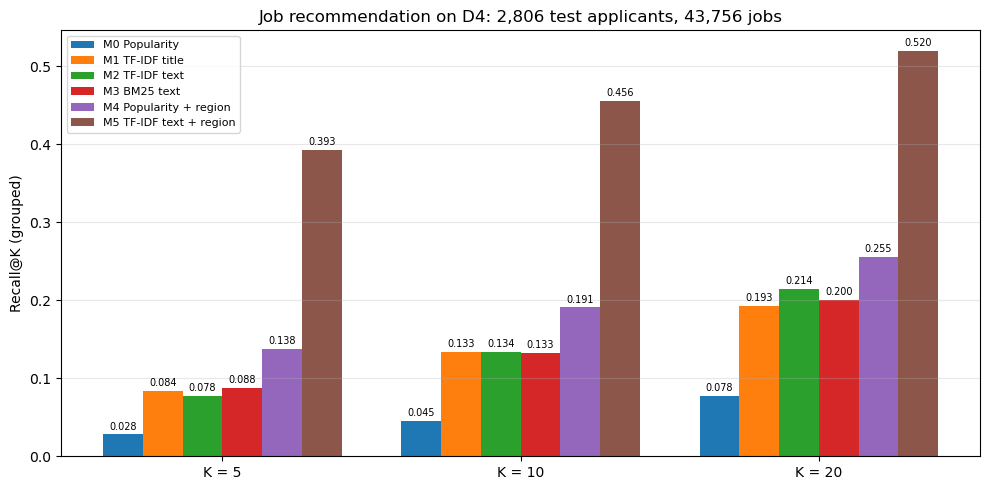

In [19]:
models = [m for m in grouped.index if m != "Random"]
x = np.arange(len(K_LIST))
width = 0.8 / len(models)

fig, ax = plt.subplots(figsize=(10, 5))
for i, m in enumerate(models):
    values = [grouped.loc[m, f"Recall@{k}"] for k in K_LIST]
    bars = ax.bar(x + (i - (len(models) - 1) / 2) * width, values, width, label=m)
    ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)

ax.set_xticks(x, [f"K = {k}" for k in K_LIST])
ax.set_ylabel("Recall@K (grouped)")
ax.set_title(f"Job recommendation on D4: {len(test):,} test applicants, {N_JOBS:,} jobs")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("results/figures/recall_by_model.png", dpi=150)
plt.show()

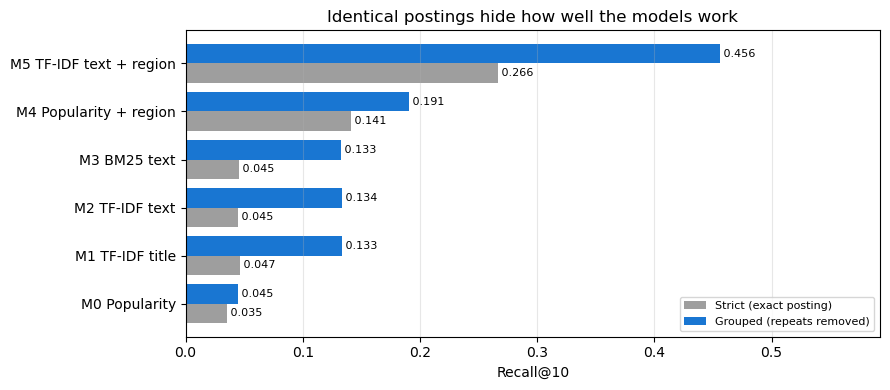

In [20]:
s = [strict.loc[m, "Recall@10"] for m in models]
g = [grouped.loc[m, "Recall@10"] for m in models]
y = np.arange(len(models))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(y - 0.2, s, 0.4, label="Strict (exact posting)", color="#9e9e9e")
ax.barh(y + 0.2, g, 0.4, label="Grouped (repeats removed)", color="#1976d2")
for i in range(len(models)):
    ax.text(s[i], i - 0.2, f" {s[i]:.3f}", va="center", fontsize=8)
    ax.text(g[i], i + 0.2, f" {g[i]:.3f}", va="center", fontsize=8)

ax.set_yticks(y, models)
ax.set_xlabel("Recall@10")
ax.set_title("Identical postings hide how well the models work")
ax.set_xlim(0, max(g) * 1.3)
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig("results/figures/strict_vs_grouped.png", dpi=150)
plt.show()

## 13. Look at real examples

In [21]:
BEST = grouped.drop("Random")["Recall@10"].idxmax()
best_lists = drop_repeats(top[BEST])
first_row = jobs.groupby("group").head(1).set_index("group")   # one posting to show per group

print("best model:", BEST)

def show(i, n=8):
    gold = set(gold_groups[i])
    print("=" * 70)
    print(f"applicant wants: {test['positionName_en'].iloc[i]}   [{test['localityName'].iloc[i][:25]}]")
    print("was invited to :", ", ".join(first_row.loc[g, "vacancyName_en"][:40] for g in gold))
    for rank, g in enumerate(best_lists[i][:n], 1):
        mark = "OK" if g in gold else "  "
        job = first_row.loc[g]
        print(f"  {rank}. [{mark}] {job['vacancyName_en'][:45]}  [{job['regionName'][:25]}]")

found  = [i for i in range(len(test)) if set(best_lists[i][:10]) & set(gold_groups[i])]
missed = [i for i in range(len(test)) if i not in set(found)]
print(f"right answer in the top 10: {len(found):,} of {len(test):,} applicants")
print()
print("### found")
for i in found[:2]:
    show(i)
print()
print("### missed")
for i in missed[:2]:
    show(i)

best model: M5 TF-IDF text + region
right answer in the top 10: 1,299 of 2,806 applicants

### found
applicant wants: Specialist   [Магаданская область, г Ма]
was invited to : Lead legal counsel, консультант отдела контрольно-правового 
  1. [  ] Court clerk  [Магаданская область]
  2. [OK] консультант отдела контрольно-правового обесп  [Магаданская область]
  3. [  ] Chief specialist  [Магаданская область]
  4. [  ] Государственный инспектор труда  [Магаданская область]
  5. [  ] главный специалист внутреннего финансового ау  [Магаданская область]
  6. [  ] ведущий специалист юридического отдела  [Магаданская область]
  7. [  ] Ведущий специалист Управления культуры, спорт  [Магаданская область]
  8. [  ] Procurement specialist  [Магаданская область]
applicant wants: менеджер на Вайлдберриз   [Ульяновская область, Майн]
was invited to : Manager
  1. [OK] Manager  [Ульяновская область]
  2. [  ] Client relations manager  [Ульяновская область]
  3. [  ] Менеджер по продажам сельскохозяй

## 14. Save

In [22]:
strict.to_csv("results/baselines/metrics_strict.csv", encoding="utf-8-sig")
grouped.to_csv("results/baselines/metrics_grouped.csv", encoding="utf-8-sig")

print("saved:")
for f in ["results/baselines/metrics_strict.csv", "results/baselines/metrics_grouped.csv",
          "results/figures/recall_by_model.png", "results/figures/strict_vs_grouped.png"]:
    print("  ", f)

saved:
   results/baselines/metrics_strict.csv
   results/baselines/metrics_grouped.csv
   figures/recall_by_model.png
   figures/strict_vs_grouped.png


## What the results mean

1. **Compare with Random, not with 100%.** Picking 10 jobs out of 43,000 is very hard,
   and most people were invited to only one job. The question is how many times better
   than guessing each model is.
2. **Strict and Grouped tell different stories.** Under Strict, the text models look only a
   little better than Popularity. Under Grouped, they are much better. The Strict score hides
   the fact that the models do find the right kind of job.
3. **Region matters most.** Most people are invited to jobs in their own region, so pushing
   those jobs to the top gives the biggest gain.
4. **M4 vs M5** separates the two effects. M4 uses only the region, M5 uses the region and
   the resume text. The gap between them is what reading the resume adds.